# Kafka to a governed lakehouse: throughput, freshness and data quality

Stale data, rejected events and repeated updates complicate streaming delivery. This notebook uses a LakeLogic contract to validate Kafka ride events, merge accepted records into Delta or Iceberg, and quarantine failures with reasons.

Measure three things:
- **Capacity:** time to clear a backlog.
- **Freshness:** accepted-event generation to write completion.
- **Accountability:** accepted and rejected counts against expected input.

RideFlow is fictional; all events are synthetic. Results describe your local environment, not production guarantees.

**Before running:** use a dedicated test broker. The notebook deletes benchmark topics and resets output folders. Start small: events and read-back tables use local memory. Colab starts Kafka and installs Java if needed; locally, use Docker or `KAFKA_BOOTSTRAP`. Spark needs compatible Java and may need additional Windows tooling.


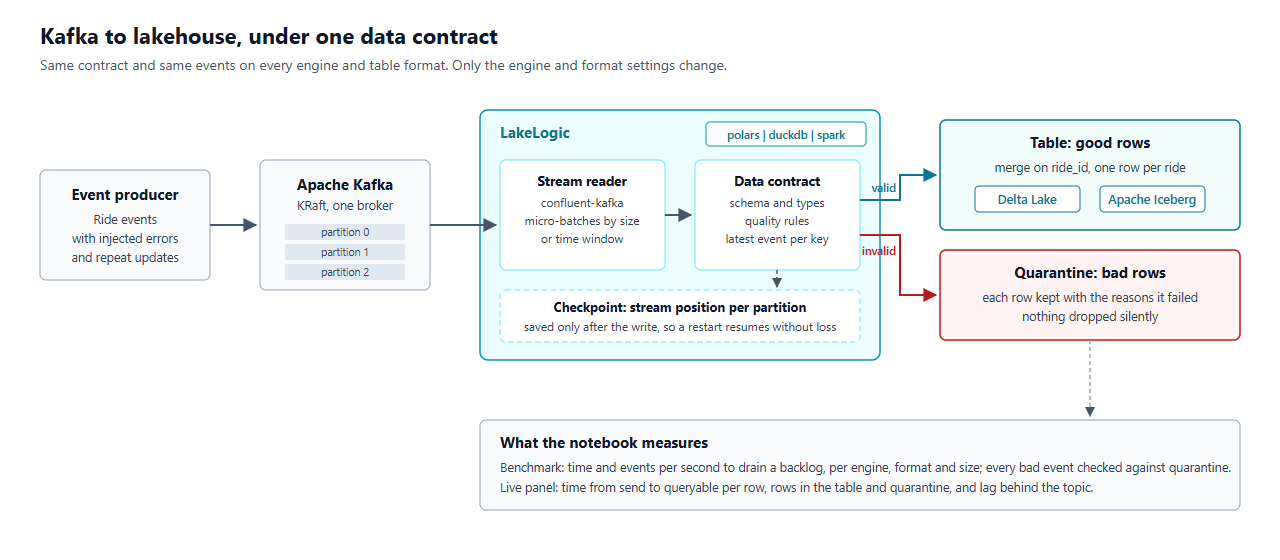

## 1. Choose the workload

Start small, then increase `SIZES` or add formats. Size comments are illustrative scenarios. `SIZES` counts original events; `UPDATE_RATIO` adds messages for existing valid rides. `ERROR_RATIO` controls faults in the original events.


In [ ]:
ENGINES = ["polars", "duckdb", "spark"]  # any of "polars", "duckdb", "spark"
STORAGES = ["delta"]  # table formats to compare: "delta", "iceberg" or both
SIZES = [
    3_000,  # orders/payments, 10/s,  5-min run   - small business stream
    30_000,  # rides/bookings, 100/s,  5-min run   - typical operational stream
    100_000,  # app events,     300/s,  5-min run   - busy product stream
    # 360_000,  # rides/bookings, 100/s,  hourly run  - same stream, scheduled hourly
    # 1_000_000,  # catch-up after a ~1h outage at 300/s, or a first backfill (needs more than free Colab)
]
ERROR_RATIO = 0.10  # share of events that are broken (0.0 to 1.0)

# How the broken events are split. Weights, not percentages.
ERROR_MIX = {
    "negative_fare": 4,  # fails the quality rule  fare > 0
    "missing_ride_id": 2,  # required field is null
    "fare_not_a_number": 2,  # wrong type: fare = "abc"
    "malformed_json": 1,  # the message is not JSON at all
    "not_an_object": 1,  # valid JSON, but a list instead of an object
}
UPDATE_RATIO = 0.05  # share of valid rides sent twice (a later status); the merge keeps one row each

PARTITIONS = 3
BATCH_SIZE = 50_000  # events per micro-batch (polars / duckdb)
KAFKA_BOOTSTRAP = ""  # leave empty to start a local broker; or e.g. "localhost:9092"
WORKDIR = "streaming_benchmark"

## 2. Install dependencies

Installs missing packages in this kernel. Use an isolated environment. Set `LAKELOGIC_SPEC` for a local checkout; otherwise the published package is used. Record package versions, OS, CPU, RAM and storage when sharing results; dependencies are not fully locked.


In [ ]:
import importlib.util
import os
import subprocess
import sys

import shutil


def pip(*pkgs):
    """Install into this kernel's Python: pip when it has one, else uv (a uv-made venv has no pip)."""
    if importlib.util.find_spec("pip") is not None:
        cmd = [sys.executable, "-m", "pip", "install", "-q", *pkgs]
    elif shutil.which("uv"):
        cmd = ["uv", "pip", "install", "-q", "--python", sys.executable, *pkgs]
    else:
        raise RuntimeError(f"No pip or uv for {sys.executable}. Install these yourself: {' '.join(pkgs)}")
    subprocess.run(cmd, check=True)


# LAKELOGIC_SPEC lets you test a local checkout, e.g.  -e "/path/to/lakelogic[kafka]"
spec = os.environ.get("LAKELOGIC_SPEC", "lakelogic[kafka]")
if importlib.util.find_spec("lakelogic") is None or os.environ.get("LAKELOGIC_SPEC"):
    pip(*spec.split())
if importlib.util.find_spec("confluent_kafka") is None:
    pip("confluent-kafka>=2.6")
if "iceberg" in STORAGES and importlib.util.find_spec("sqlalchemy") is None:
    pip("pyiceberg[sql-sqlite]>=0.11.1,<0.12")  # Iceberg through a local SQLite catalog
if "spark" in ENGINES and importlib.util.find_spec("delta") is None:
    pip("pyspark==4.0.1", "delta-spark==4.0.0", "importlib-metadata")
for mod in ("matplotlib", "pandas"):
    if importlib.util.find_spec(mod) is None:
        pip(mod)

import lakelogic
from lakelogic.core import stream_sink

print("lakelogic", lakelogic.__version__)
print(
    "Kafka client:",
    "confluent-kafka (librdkafka)"
    if stream_sink.__dict__.get("_confluent_available", lambda: False)()
    else "kafka-python",
)

## 3. Start Kafka

Uses `KAFKA_BOOTSTRAP`, or starts one local broker through Docker. Without Docker, Colab/Linux installs Java if needed and runs Kafka in KRaft mode.


In [ ]:
import socket
import time
import urllib.request
import tarfile
from pathlib import Path

KAFKA_VERSION = "4.1.0"


def _port_open(host, port):
    try:
        with socket.create_connection((host, port), timeout=1):
            return True
    except OSError:
        return False


def _wait_for(host, port, seconds=120):
    t0 = time.time()
    while time.time() - t0 < seconds:
        if _port_open(host, port):
            time.sleep(3)  # the port opens a moment before the broker accepts requests
            return
        time.sleep(1)
    raise RuntimeError(f"Kafka did not start on {host}:{port} within {seconds}s")


def _java_ok():
    if shutil.which("java") is None:
        return False
    out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
    return any(f'version "{v}' in out for v in range(17, 30))


def ensure_java():
    if _java_ok():
        return
    if shutil.which("apt-get") is None:
        raise RuntimeError(
            "Java 17+ is needed. Install it, or run Kafka in Docker / elsewhere and set KAFKA_BOOTSTRAP."
        )
    subprocess.run(
        "apt-get -qq update && (apt-get -qq install -y openjdk-17-jre-headless || apt-get -qq install -y openjdk-21-jre-headless) > /dev/null",
        shell=True,
        check=True,
    )
    jvm = sorted(Path("/usr/lib/jvm").glob("java-*-openjdk-*"))
    if jvm:
        os.environ["JAVA_HOME"] = str(jvm[0])


def start_kafka():
    if KAFKA_BOOTSTRAP:
        return KAFKA_BOOTSTRAP
    if _port_open("localhost", 9092):
        print("Using the broker already on localhost:9092")
        return "localhost:9092"
    if shutil.which("docker") and subprocess.run(["docker", "info"], capture_output=True).returncode == 0:
        subprocess.run(["docker", "rm", "-f", "ll-bench-kafka"], capture_output=True)
        subprocess.run(
            ["docker", "run", "-d", "--name", "ll-bench-kafka", "-p", "9092:9092", f"apache/kafka:{KAFKA_VERSION}"],
            check=True,
            capture_output=True,
        )
        _wait_for("localhost", 9092)
        print("Started Kafka in Docker (container ll-bench-kafka)")
        return "localhost:9092"
    # Colab / plain Linux: download Kafka and run it in KRaft mode (no ZooKeeper).
    ensure_java()
    home = Path(f"kafka_2.13-{KAFKA_VERSION}")
    if not home.exists():
        url = f"https://archive.apache.org/dist/kafka/{KAFKA_VERSION}/kafka_2.13-{KAFKA_VERSION}.tgz"
        urllib.request.urlretrieve(url, "kafka.tgz")
        with tarfile.open("kafka.tgz") as t:
            t.extractall(".")
    cfg = home / "config" / "server.properties"
    env = {**os.environ, "KAFKA_HEAP_OPTS": "-Xmx512m -Xms512m"}
    logs = Path("/tmp/kraft-combined-logs")
    if not (logs / "meta.properties").exists():
        cid = subprocess.run(
            [str(home / "bin" / "kafka-storage.sh"), "random-uuid"], capture_output=True, text=True, env=env
        ).stdout.strip()
        subprocess.run(
            [str(home / "bin" / "kafka-storage.sh"), "format", "--standalone", "-t", cid, "-c", str(cfg)],
            check=True,
            capture_output=True,
            env=env,
        )
    subprocess.Popen(
        [str(home / "bin" / "kafka-server-start.sh"), str(cfg)],
        stdout=open("kafka.log", "w"),
        stderr=subprocess.STDOUT,
        env=env,
    )
    _wait_for("localhost", 9092)
    print(f"Started Kafka {KAFKA_VERSION} (KRaft) on localhost:9092, log in kafka.log")
    return "localhost:9092"


BOOTSTRAP = start_kafka()

## 4. Generate test events

Each configuration gets its own topic. A seeded generator creates rides, five fault types and updates. IDs and fault choices are reproducible for fixed settings; timestamps vary. These fixtures are not a production workload model.


In [ ]:
import json
import random
from collections import Counter
from confluent_kafka import Producer
from confluent_kafka.admin import AdminClient, NewTopic

STATUSES = ["requested", "accepted", "completed"]


def make_event(i, rnd, error_ratio, injected):
    """One message as bytes, and its ride_id when the event is valid (else None)."""
    ride = {
        "ride_id": i,
        "status": rnd.choice(STATUSES),
        "fare": round(rnd.uniform(5, 80), 2),
        "city": rnd.choice(["London", "Lagos", "Leeds"]),
        "event_ms": int(time.time() * 1000),
    }
    if rnd.random() >= error_ratio:
        return json.dumps(ride).encode(), i
    kinds, weights = zip(*ERROR_MIX.items())
    kind = rnd.choices(kinds, weights)[0]
    injected[kind] += 1
    if kind == "malformed_json":
        return b'{"ride_id": ' + str(i).encode() + b', "status": "compl', None
    if kind == "not_an_object":
        return json.dumps([i, "completed"]).encode(), None
    if kind == "negative_fare":
        ride["fare"] = -ride["fare"]
    elif kind == "missing_ride_id":
        ride["ride_id"] = None
    elif kind == "fare_not_a_number":
        ride["fare"] = "abc"
    return json.dumps(ride).encode(), None


def make_events(n, error_ratio, seed=7):
    """Return (messages as bytes, what was injected, number of valid rides)."""
    rnd = random.Random(seed)
    injected = Counter()
    msgs, valid_ids = [], []
    for i in range(1, n + 1):
        msg, valid = make_event(i, rnd, error_ratio, injected)
        msgs.append(msg)
        if valid is not None:
            valid_ids.append(valid)
    # Updates: a later message for an existing valid ride. The merge keeps one row per ride_id.
    for rid in rnd.sample(valid_ids, int(len(valid_ids) * UPDATE_RATIO)):
        msgs.append(
            json.dumps(
                {
                    "ride_id": rid,
                    "status": "completed",
                    "fare": 42.0,
                    "city": "London",
                    "event_ms": int(time.time() * 1000),
                }
            ).encode()
        )
        injected["update_of_existing_ride"] += 1
    return msgs, injected, len(valid_ids)


def create_topic(topic):
    admin = AdminClient({"bootstrap.servers": BOOTSTRAP})
    for f in admin.delete_topics([topic]).values():
        try:
            f.result()
        except Exception:
            pass  # the topic did not exist
    # Kafka deletes in the background, so retry the create until the old topic is gone.
    for _ in range(30):
        try:
            for f in admin.create_topics([NewTopic(topic, PARTITIONS, 1)]).values():
                f.result()
            return
        except Exception as e:
            if "already exists" not in str(e) and "marked for deletion" not in str(e):
                raise
            time.sleep(1)
    raise RuntimeError(f"Topic {topic} was not recreated within 30s")


def produce(topic, msgs):
    create_topic(topic)
    p = Producer({"bootstrap.servers": BOOTSTRAP, "linger.ms": 20, "batch.num.messages": 10000})
    t0 = time.perf_counter()
    for i, m in enumerate(msgs):
        while True:
            try:
                p.produce(topic, m)
                break
            except BufferError:
                p.poll(0.1)
        if i % 10000 == 0:
            p.poll(0)
    p.flush()
    return time.perf_counter() - t0

## 5. Define the contract

Share the schema, rule and merge key across configurations. Accepted rides merge on `ride_id`; failures go to Delta quarantine with reasons.

- **Delta:** local path writes.
- **Iceberg:** SQLite/PyIceberg for Polars and DuckDB; Hadoop catalog for Spark.
- **Quarantine:** explicitly Delta, including for Iceberg targets.

Catalog/write paths differ, so this does not isolate format performance. Production also needs supported integrations, storage, credentials and permissions.


In [ ]:
import re
import yaml

ICEBERG_CATALOG = {  # polars / duckdb (pyiceberg). Relative paths also work on Windows.
    "iceberg_catalog_type": "sql",
    "iceberg_catalog_uri": f"sqlite:///{WORKDIR}/iceberg_catalog.db",
    "iceberg_catalog_warehouse": f"{WORKDIR}/iceberg_warehouse",
}


def iceberg_table(run_dir):
    """The Iceberg identifier for a run: catalog.namespace.table, one namespace per run."""
    return f"local.{re.sub(r'[^a-z0-9_]', '_', run_dir.name.lower())}.rides"


def pyiceberg_catalog():
    from pyiceberg.catalog import load_catalog

    return load_catalog(
        "local",
        type="sql",
        uri=ICEBERG_CATALOG["iceberg_catalog_uri"],
        warehouse=ICEBERG_CATALOG["iceberg_catalog_warehouse"],
    )


def reset_iceberg_table(engine, ident):
    """Drop a run's table so a rerun of the notebook starts empty."""
    if engine == "spark":
        _, ns, _ = ident.split(".")
        spark.sql(f"CREATE NAMESPACE IF NOT EXISTS local.{ns}")
        spark.sql(f"DROP TABLE IF EXISTS {ident}")
        return
    cat = pyiceberg_catalog()
    try:
        cat.drop_table(".".join(ident.split(".")[1:]))
    except Exception:
        pass


def write_contract(run_dir, topic, engine="polars", storage="delta"):
    contract = {
        "version": "1.0.0",
        "info": {"title": "rides"},
        "dataset": "rides",
        "primary_key": ["ride_id"],
        "source": {
            "type": "stream",
            "options": {
                "kind": "kafka",
                "topic": topic,
                "brokers": BOOTSTRAP,
                "group_id": "lakelogic-bench",
                "batch_size": BATCH_SIZE,
                "trigger": "available_now",
                "checkpoint": str(run_dir / "_checkpoints" / "rides"),
            },
        },
        "model": {
            "fields": [
                {"name": "ride_id", "type": "long", "required": True},
                {"name": "status", "type": "string"},
                {"name": "fare", "type": "double"},
                {"name": "city", "type": "string"},
                {"name": "event_ms", "type": "long"},
            ]
        },
        "quality": {"row_rules": [{"name": "fare_positive", "sql": "fare > 0"}]},
        "materialization": {"strategy": "merge", "format": "delta", "target_path": str(run_dir / "rides")},
        "quarantine": {"target": str(run_dir / "rides_quarantine"), "format": "delta"},
    }
    if storage == "iceberg":
        ident = iceberg_table(run_dir)
        reset_iceberg_table(engine, ident)
        contract["materialization"] = {"strategy": "merge", "format": "iceberg", "target_path": f"table:{ident}"}
        if engine != "spark":
            contract["metadata"] = dict(ICEBERG_CATALOG)
    path = run_dir / "rides.yaml"
    path.write_text(yaml.safe_dump(contract, sort_keys=False))
    return path

## 6. Create local Spark, when selected

**Spark runs locally**, using this machine's cores (`local[*]`). Results do not capture potential distributed gains or rank engines at scale. Kafka, Delta and Iceberg connectors are configured here.

Session creation is outside the timer; first-use work can still affect measured execution for all engines.


In [ ]:
spark = None
if "spark" in ENGINES:
    ensure_java()
    from pyspark.sql import SparkSession
    from delta import configure_spark_with_delta_pip

    builder = (
        SparkSession.builder.appName("lakelogic-streaming-benchmark")
        .master("local[*]")
        .config(
            "spark.sql.extensions",
            "io.delta.sql.DeltaSparkSessionExtension,org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions",
        )
        .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
        .config("spark.sql.catalog.local", "org.apache.iceberg.spark.SparkCatalog")
        .config("spark.sql.catalog.local.type", "hadoop")
        .config("spark.sql.catalog.local.warehouse", str(Path(WORKDIR, "spark_iceberg").resolve()))
        .config("spark.sql.shuffle.partitions", "4")
        .config("spark.ui.showConsoleProgress", "false")
    )
    spark = configure_spark_with_delta_pip(
        builder,
        extra_packages=[
            "org.apache.spark:spark-sql-kafka-0-10_2.13:4.0.1",
            "org.apache.iceberg:iceberg-spark-runtime-4.0_2.13:1.10.0",
        ],
    ).getOrCreate()
    spark.sparkContext.setLogLevel("ERROR")
    print("Spark", spark.version)

## 7. Process the backlog and reconcile counts

Publish events, run the contract, then read accepted and quarantine tables back. The `available_now` timer covers processor construction, consumption, validation, writes and checkpoint handling. It excludes generation, Kafka publishing and read-back. This is backlog throughput, not per-event latency.

Each configuration runs **once**, in fixed order. Repeat trials and investigate outliers before choosing an engine; no cost comparison is measured.

`COUNTS MATCH` checks accepted-table and quarantine counts only. It does not verify record IDs, final updates or recovery. Merged updates mean accepted messages can exceed final table rows.


In [ ]:
import logging
import pandas as pd
import polars as pl
from lakelogic import DataProcessor

try:  # keep the output to the results; LakeLogic logs through loguru
    from loguru import logger as _lg

    _lg.remove()
    _lg.add(sys.stderr, level="WARNING")
except Exception:
    pass


def read_delta(path):
    """Read the Delta table at path, or the one inside it (the quarantine target is a folder that
    holds one table per dataset, e.g. rides_quarantine/rides)."""
    path = Path(path)
    tables = [path] if (path / "_delta_log").exists() else [p.parent for p in path.rglob("_delta_log")]
    if not tables:
        return pl.DataFrame()
    return pl.concat([pl.read_delta(str(t)) for t in tables], how="diagonal_relaxed")


def read_good(run_dir, engine, storage):
    """The good-rows table of a run, as a polars frame."""
    if storage == "delta":
        return read_delta(run_dir / "rides")
    ident = iceberg_table(run_dir)
    try:
        if engine == "spark":
            return pl.from_pandas(spark.table(ident).toPandas())
        return pl.from_arrow(pyiceberg_catalog().load_table(".".join(ident.split(".")[1:])).scan().to_arrow())
    except Exception:
        return pl.DataFrame()  # not created yet


def run_once(engine, storage, n):
    run_dir = Path(WORKDIR) / f"{engine}_{storage}_{n}"
    shutil.rmtree(run_dir, ignore_errors=True)
    run_dir.mkdir(parents=True)
    topic = f"rides_{engine}_{storage}_{n}"
    msgs, injected, n_valid = make_events(n, ERROR_RATIO)
    produce_s = produce(topic, msgs)
    contract = write_contract(run_dir, topic, engine, storage)

    t0 = time.perf_counter()
    result = DataProcessor(str(contract), engine=engine).run_source()
    process_s = time.perf_counter() - t0
    s = result.stream_summary

    good = read_good(run_dir, engine, storage)
    bad = read_delta(run_dir / "rides_quarantine")
    expected_bad = sum(v for k, v in injected.items() if k != "update_of_existing_ride")
    return {
        "engine": engine,
        "storage": storage,
        "events": len(msgs),
        "produce_s": round(produce_s, 2),
        "process_s": round(process_s, 2),
        "events_per_s": int(len(msgs) / process_s),
        "batches": s.get("batches"),
        "good_rows_in_table": good.height,
        "expected_good_rows": n_valid,
        "quarantined": bad.height,
        "expected_quarantined": expected_bad,
        "bad_reported": s.get("bad_count"),
        "superseded_in_batch": s.get("superseded_count"),
        "check": "COUNTS MATCH" if (good.height == n_valid and bad.height == expected_bad) else "MISMATCH",
        "_bad": bad,
        "_injected": injected,
    }


Path(WORKDIR).mkdir(exist_ok=True)
results = []
for engine in ENGINES:
    for storage in STORAGES:
        for n in SIZES:
            print(f"{engine:7} {storage:8} {n:>10,} events ...", end=" ", flush=True)
            r = run_once(engine, storage, n)
            results.append(r)
            print(f"{r['process_s']:>7.2f}s  {r['events_per_s']:>9,} events/s  {r['check']}")

table = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in results])
table

## 8. Compare time and throughput

Throughput counts all Kafka messages, including updates and faults, per processing second. It is not unique valid rows per second. Solid lines: Delta; dashed: Iceberg.

Compare backlog time with your recovery window. Test sustained arrival rates separately before setting production capacity targets.


In [ ]:
import matplotlib.pyplot as plt

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
COLORS = {"polars": "#0891b2", "duckdb": "#d97706", "spark": "#7c3aed"}
for (engine, storage), g in table.groupby(["engine", "storage"]):
    style = dict(
        marker="o",
        color=COLORS.get(engine),
        linestyle="-" if storage == "delta" else "--",
        label=f"{engine} / {storage}",
    )
    a.plot(g["events"], g["process_s"], **style)
    b.plot(g["events"], g["events_per_s"], **style)
a.set(title="Processing time", xlabel="events", ylabel="seconds")
b.set(title="Throughput", xlabel="events", ylabel="events per second")
for ax in (a, b):
    ax.set_xscale("log")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Inspect rejection reasons

For the largest workload, group quarantined rows by their most specific matching error text and compare with injected fault counts. This diagnostic checks aggregate categories, not each record's identity or untested failure types. Error wording may change between versions.


In [ ]:
ROOT_CAUSE = [  # most specific first
    ("malformed_json", "not valid JSON"),
    ("not_an_object", "not a JSON object"),
    ("fare_not_a_number", "cannot be cast"),
    ("missing_ride_id", "ride_id_required"),
    ("negative_fare", "fare_positive"),
]


def root_causes(bad):
    err = next((c for c in bad.columns if c.endswith("_errors")), None)
    if err is None or bad.height == 0:
        return Counter()
    text = bad[err].cast(pl.List(pl.Utf8)).list.join(" | ")
    cause = pl.lit("other")
    for kind, needle in reversed(ROOT_CAUSE):
        cause = pl.when(pl.col("t").str.contains(needle, literal=True)).then(pl.lit(kind)).otherwise(cause)
    return Counter(dict(pl.DataFrame({"t": text}).select(cause.alias("k"))["k"].value_counts().iter_rows()))


biggest = [r for r in results if r["events"] == max(x["events"] for x in results)]
rows = []
for kind in [k for k, _ in ROOT_CAUSE] + ["other"]:
    row = {"error": kind, "injected": biggest[0]["_injected"].get(kind, 0)}
    for r in biggest:
        row[f"{r['engine']} / {r['storage']}"] = root_causes(r["_bad"]).get(kind, 0)
    rows.append(row)
caught = pd.DataFrame(rows)
caught

Example rejected records and their recorded reasons:


In [ ]:
r = biggest[0]
err = next(c for c in r["_bad"].columns if c.endswith("_errors"))
with pl.Config(fmt_str_lengths=80, tbl_width_chars=160):
    print(r["_bad"].select("ride_id", "fare", err).head(8))

## 10. Reuse a completed checkpoint

Rerun the final configuration without new messages. Inspect the printed source count: zero supports checkpoint reuse after success. This is not a crash-recovery or exactly-once test, and the cell does not assert the result.


In [ ]:
r = results[-1]
run_dir = Path(WORKDIR) / f"{r['engine']}_{r['storage']}_{SIZES[-1]}"
again = DataProcessor(str(run_dir / "rides.yaml"), engine=r["engine"]).run_source().stream_summary
print(
    f"{r['engine']} / {r['storage']}: second run read",
    again.get("source_count"),
    "events; the table still has",
    read_good(run_dir, r["engine"], r["storage"]).height,
    "rows",
)

## 11. Observe freshness under steady load

The live demo uses **Polars or DuckDB**, not Spark. Watch accepted counts, quarantine reasons and Kafka lag while events arrive.

**Latency:** accepted-event generation timestamp to the return of its micro-batch `materialize()` call. This approximates write completion, not independently measured query visibility. It includes buffering, batch waiting and materialization work; rejected events are excluded.

The producer rate is a target. Panel reads can affect this shared machine, although refresh timing does not define latency. This short demo does not establish sustained capacity or resilience.


In [ ]:
LIVE_ENGINE = "polars"  # "polars" or "duckdb"
LIVE_STORAGE = "delta"  # "delta" or "iceberg"
RATE = 500  # events per second
LIVE_SECONDS = 60  # how long the producer runs
LIVE_BATCH_SIZE = 1_000  # a micro-batch closes at this many events...
WINDOW_SECONDS = 1.0  # ...or after this many seconds, whichever comes first
REFRESH_SECONDS = 1.0

In [ ]:
import threading
from IPython.display import clear_output
from lakelogic import SQLiteCheckpointStore, StreamSink
from lakelogic.core.stream_sink import KafkaOffsetSource
from confluent_kafka import Consumer, TopicPartition

live_dir = Path(WORKDIR) / f"live_{LIVE_ENGINE}_{LIVE_STORAGE}"
shutil.rmtree(live_dir, ignore_errors=True)
live_dir.mkdir(parents=True)
LIVE_TOPIC = f"rides_live_{LIVE_ENGINE}_{LIVE_STORAGE}"
create_topic(LIVE_TOPIC)
live_contract = write_contract(live_dir, LIVE_TOPIC, LIVE_ENGINE, LIVE_STORAGE)
ckpt_path = live_dir / "_checkpoints" / "live.sqlite"
ckpt_path.parent.mkdir(parents=True, exist_ok=True)

stop_producing = threading.Event()
live = {"sent": 0, "injected": Counter(), "error": None}


def producer_loop():
    rnd = random.Random(11)
    p = Producer({"bootstrap.servers": BOOTSTRAP, "linger.ms": 5})
    i, t0 = 0, time.time()
    while not stop_producing.is_set() and time.time() - t0 < LIVE_SECONDS:
        due = int((time.time() - t0) * RATE)  # keep a steady rate
        while i < due:
            i += 1
            msg, _ = make_event(i, rnd, ERROR_RATIO, live["injected"])
            p.produce(LIVE_TOPIC, msg)
        p.poll(0)
        time.sleep(0.01)
    p.flush()
    live["sent"] = i


source = KafkaOffsetSource(LIVE_TOPIC, brokers=BOOTSTRAP, group_id="lakelogic-live")
sink = StreamSink(
    contract=str(live_contract),
    source=source,
    engine=LIVE_ENGINE,
    checkpoint=SQLiteCheckpointStore(ckpt_path),
    checkpoint_key="live",
    batch_size=LIVE_BATCH_SIZE,
    window_seconds=WINDOW_SECONDS,
)

lat_points = []  # (seconds since start, latency in ms), one per good row, recorded at commit
t_start = time.time()
_write = sink.processor.materialize


def _event_ms(frame):
    """The event_ms column of a polars frame or a DuckDB relation."""
    if hasattr(frame, "get_column"):
        return frame.get_column("event_ms").to_list()
    return pl.from_arrow(frame.select("event_ms").arrow())["event_ms"].to_list()


def timed_write(good, bad, target_path=None):
    out = _write(good, bad, target_path=target_path)
    done_ms = time.time() * 1000  # the batch is written: write completion, not measured query visibility
    t = time.time() - t_start
    lat_points.extend((t, done_ms - ev) for ev in _event_ms(good) if ev is not None)
    return out


sink.processor.materialize = timed_write


def sink_loop():
    try:
        live["summary"] = sink.run("continuous")
    except Exception as e:  # shown in the panel instead of dying silently in a thread
        live["error"] = repr(e)


threading.Thread(target=producer_loop, daemon=True).start()
sink_thread = threading.Thread(target=sink_loop, daemon=True)
sink_thread.start()
print(f"Sending {RATE} events/s for {LIVE_SECONDS}s to {LIVE_TOPIC}; streaming into {live_dir}")

In [ ]:
import numpy as np

watch = Consumer({"bootstrap.servers": BOOTSTRAP, "group.id": "lakelogic-live-watch"})
end_at = t_start + LIVE_SECONDS + 15  # keep watching after the producer stops, to see the stream catch up


def end_offset_total():
    return sum(watch.get_watermark_offsets(TopicPartition(LIVE_TOPIC, p), timeout=5)[1] for p in range(PARTITIONS))


def committed_total():
    c = SQLiteCheckpointStore(ckpt_path).load("live")
    return sum((c.cursor or {}).values()) if c else 0


while time.time() < end_at:
    good = read_good(live_dir, LIVE_ENGINE, LIVE_STORAGE)
    bad = read_delta(live_dir / "rides_quarantine")
    points = list(lat_points)
    recent = [l for t, l in points if t > time.time() - t_start - 15]
    lag = max(end_offset_total() - committed_total(), 0)

    clear_output(wait=True)
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(15, 3.6))
    if points:
        ts, ls = zip(*points)
        a.scatter(ts, np.array(ls) / 1000, s=2, alpha=0.3)
    a.set(title="Send to written, per row (s)", xlabel="seconds since start", ylabel="seconds")
    a.grid(alpha=0.3)
    b.bar(
        [f"in {LIVE_STORAGE}", "quarantined", "lag"],
        [good.height, bad.height, lag],
        color=["#0891b2", "#dc2626", "#64748b"],
    )
    b.set(title="Rows")
    b.grid(alpha=0.3, axis="y")
    causes = root_causes(bad)
    c.barh(list(causes) or ["none yet"], list(causes.values()) or [0], color="#dc2626")
    c.set(title="Quarantined, by reason")
    c.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()
    if recent:
        print(
            f"last 15s latency: median {np.median(recent) / 1000:.2f}s  p95 {np.percentile(recent, 95) / 1000:.2f}s  "
            f"max {max(recent) / 1000:.2f}s   |  lag {lag:,} events"
        )
    if live["error"]:
        print("stream error:", live["error"])
    time.sleep(REFRESH_SECONDS)

watch.close()

### Stop and reconcile

Run after the panel finishes. Compare sent, accepted and rejected counts and inspect whole-run latency. The panel shows a recent window. If the consumer has not stopped after the join timeout, counts are not final; stop it before restarting.


In [ ]:
stop_producing.set()
source.drain = True  # the next empty poll ends the continuous run
sink_thread.join(timeout=60)

all_lat = np.array([l for _, l in lat_points]) / 1000
good = read_good(live_dir, LIVE_ENGINE, LIVE_STORAGE)
bad = read_delta(live_dir / "rides_quarantine")
print(
    f"sent {live['sent']:,} events at {RATE}/s  ->  {good.height:,} rows in {LIVE_STORAGE}, {bad.height:,} quarantined"
)
print(f"broken events injected {sum(live['injected'].values()):,}, quarantined {bad.height:,}")
if len(all_lat):
    print(
        f"latency, send to written: median {np.median(all_lat):.2f}s, "
        f"p95 {np.percentile(all_lat, 95):.2f}s, max {all_lat.max():.2f}s"
    )

## 12. Clean up

Removes the fixed-name benchmark Docker container, if present, and stops Spark. Check container ownership first. External topics, local outputs/checkpoints and non-Docker Kafka processes remain; stop those processes separately or end Colab.


In [ ]:
if shutil.which("docker"):
    subprocess.run(["docker", "rm", "-f", "ll-bench-kafka"], capture_output=True)
if spark is not None:
    spark.stop()

## Take this into delivery

One reviewable contract brings ingestion, validation, merge and quarantine settings together. Rejected records remain available for investigation.

Before making production promises, repeat measurements, record the environment, verify IDs and update values, test crash/replay recovery, and use representative platform settings. Measure cost separately.

**Next:** run the smallest workload, inspect both outputs, then adapt the contract and fault fixtures to your source.
